## Abstract

We added a helix penalty that shifted ESMFold2 binder designs toward β-sheets across five targets. The shift began early in optimization and increased the number passing a sheet-content and confidence screen, despite lower average confidence.

----

:::{.callout-note title="AI usage disclosure" collapse="true"}
We used ChatGPT (GPT-6 Astra) and Claude (Opus 5.5) to help write code, clean up code, comment our code, and review our code. We also used it to suggest wording ideas, write text, expand on summary text that we provided, copy-edit draft text to match Arcadia's style, and clarify and streamline text. Additionally, we used ChatGPT and Claude to generate figure mockups, generate scientific ideas, interpret our data, and suggest experiments. ChatGPT and Claude also suggested papers on relevant science, we did further reading, and we cited some of this literature. We reviewed all AI-assisted content and take responsibility for its accuracy and integrity.
:::

## Purpose

We observed that ESMFold2 generated designs with higher α-helical content than natural proteins. We wanted to bring their secondary-structure compositions closer to those found in nature, without retraining the model.

We added a penalty for helix-like geometry that increased β-sheet and loop content across five targets, with lower confidence scores on average. We're sharing the code, predicted structures, and optimization traces for researchers who want to control binder composition or investigate how structural preferences emerge during design. These experiments establish how steering changes computational predictions. Whether the resulting proteins fold and bind their intended targets remains to be tested.

## Introduction

ESMFold2 is a structure prediction model that uses representations from the ESMC protein language model to predict proteins and their complexes. Alongside the model, @candido2026language present a binder-design algorithm that combines structural feedback from ESMFold2 with sequence feedback from ESMC. Starting from a soft sequence — a probability distribution over amino acids at each position — the algorithm repeatedly predicts the binder–target complex, evaluates a design objective, and updates the candidate sequence. As optimization proceeds, the algorithm progressively hardens the soft sequence into a discrete amino acid sequence. The weights of both ESMC and ESMFold2 remain frozen, allowing researchers to design proteins under different objectives without retraining or fine-tuning either model. This approach builds on earlier work in protein hallucination and gradient-based sequence optimization [@anishchenko2021hallucination; @norn2021landscape; @frank2024relaxed], and BindCraft popularized it for binder design [@pacesa2025bindcraft].

Although training data, model architectures, design objectives, and filtering choices differ among methods, several binder-design workflows favor α-helical designs. BindCraft reports this tendency in its confidence-driven designs [@pacesa2025bindcraft], and RFdiffusion's developers note that the default model often generates predominantly helical binders [@rosettacommons2025rfdiffusiondocs]. We observed a similar enrichment in unsteered ESMFold2 designs, which led us to investigate how we could change this preference.

Reducing this preference could benefit binder design in several ways. First, sampling a wider range of folds could increase the chance of finding a successful binder while reducing the effort spent screening structurally redundant candidates. Second, natural binders provide examples of secondary-structure compositions that support binding. We reasoned that steering generation toward these compositions could offer a useful evolutionary starting point for design. Third, alternative structural compositions could help designs reach binding sites that favor different interface geometries. This last possibility has experimental support: Guiding RFdiffusion toward β-strand pairing at exposed β-sheet edges produced binders to targets including ALK-3 and KIT, where earlier design campaigns had failed [@sappington2026betapairing]. Such results motivate exploring alternatives to predominantly helical designs.

BindCraft already uses a helicity loss to obtain sheet-rich designs, with a decrease in computational screening success [@pacesa2025bindcraft]. But to our knowledge, secondary-structure steering with a helicity penalty has not been demonstrated for ESMFold2. Understanding where the preference arises could also reveal other ways to intervene: a helical final design may reflect a preference already present in the initial prediction, its reinforcement during sequence optimization, or both.

Here, we investigated how to redirect ESMFold2's helix preference and how doing so affected predicted confidence. We varied the strength of a helicity penalty across targets and tracked how the predictions changed as the soft sequence became more concentrated. The penalty increased sheet content and the number of candidates passing a combined sheet-content and confidence screen, despite lowering average confidence. Helicity diverged while the amino acid probabilities remained nearly uniform, suggesting that even subtle changes to the initial distribution might influence design outcomes.

:::{.callout-note collapse="true" title="GPU computation"}

The analyses in this publication are reproducible from archived model outputs. By default, the accompanying notebook downloads these outputs and the natural-reference inputs from [Zenodo](https://doi.org/10.5281/zenodo.23542792), using them as a checkpoint to rerun all downstream analyses.

Generating candidates from scratch requires graphics processing units (GPUs). Follow the [setup guide](pages/SETUP.qmd) to run the design workflow. The design procedure isn't seed-reproducible, so new runs will generate different candidates even with the same seeds and settings.

:::

In [1]:
# | include: false

import warnings

import pandas as pd

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 40)

In [2]:
# | include: false
from analysis import (
    artifacts,
    composition,
    deposit,
    figures,
    loss_trace,
    paths,
    reference,
    targets,
)

paths.ensure_dirs()
if any(not artifacts.status(t, a).is_analysable for t, a in targets.publication_campaigns()):
    deposit.DESIGN_TABLES.fetch()

## Unsteered designs are helix-rich relative to natural proteins

We generated 30 unsteered binders per target using the five constructs from the ESMFold2 paper [@candido2026language] (@tbl-targets). We sampled binder lengths from a 60–200-residue range.

| Target | Target region | UniProt accession | UniProt residues | Target length (residues) |
|---|---|---|---|---:|
| EGFR | Domain III | [P00533](https://www.uniprot.org/uniprotkb/P00533/entry) | 334–524 | 191 |
| PDGFRβ | Domains D2–D3 | [P09619](https://www.uniprot.org/uniprotkb/P09619/entry) | 126–312 | 187 |
| PD-L1 | IgV domain | [Q9NZQ7](https://www.uniprot.org/uniprotkb/Q9NZQ7/entry) | 18–132 | 115 |
| CTLA-4 | IgV domain | [P16410](https://www.uniprot.org/uniprotkb/P16410/entry) | 38–155 | 118 |
| CD45 | Domains d3–d4 | [P08575](https://www.uniprot.org/uniprotkb/P08575/entry) | 390–574 | 185 |

: Human target constructs from Table S10 of @candido2026language. Residue ranges use canonical UniProt numbering and include both endpoints. EGFR, epidermal growth factor receptor; PDGFRβ, platelet-derived growth factor receptor β; PD-L1, programmed death-ligand 1; CTLA-4, cytotoxic T-lymphocyte-associated protein 4; CD45, cluster of differentiation 45; IgV, immunoglobulin variable-like. {#tbl-targets}

To compare their secondary-structure composition with binders found in nature, we queried the [RCSB](https://www.rcsb.org/) for experimentally resolved complexes containing exactly two distinct protein entities and selected chains within the same 60–200-residue range. We refer to each selected chain as the natural binder and the other as its target.

We then compared the helix, sheet, and loop fractions of the two groups within five binder-length bins (@fig-composition).

We used arcadia-pycolor (v0.8.0) [@arcadia-pycolor] for figure colors and plot styling throughout this publication.

:::{.callout-note collapse="true" title="Natural protein baseline construction"}

We selected X-ray structures containing two distinct protein entities and a binder with a named source organism other than "synthetic construct," retaining one representative per sequence-identity cluster. We excluded records annotated as designed proteins and chains outside the length range or with insufficient resolved backbone.

We measured natural and designed chains with PyDSSP (v0.9.1), using the same backbone-based helix, sheet, and loop assignments [@minami2024pydssp]. For designs, we measured the final binder structures predicted by ESMFold2-Experimental-Fast-Cutoff2025. We used a separate, non-Fast model for confidence reporting and screening, as described below. Only residues with N, Cα, C, and O coordinates contribute to the fractions.

In [3]:
# | code-fold: true
# | code-summary: "Measure and select the natural protein reference"

reference_pairs = reference.pairs()
eligible = (
    reference_pairs["cluster_representative"].eq(1)
    & reference_pairs["measured"].eq(1)
    & reference_pairs["binder_design_like"].eq(0)
    & reference_pairs["excluded_short_or_long"].eq(0)
    & reference_pairs["excluded_incomplete"].eq(0)
)
natural = reference_pairs.loc[eligible].reset_index(drop=True)

for setting, value in reference.recorded_query_settings().items():
    print(f"{setting}: {value}")

print(f"Retained reference: {len(natural):,} chains from {natural.pdb_id.nunique():,} PDB entries")
print(f"  Small-interface flag: {int(natural.flag_small_interface.sum()):,} chains")
print(f"  Peptide-partner flag: {int(natural.flag_peptide_target.sum()):,} chains")

using the recorded search results in natural_binder_search_hits.json, snapshot 2026-09-02
downloading 2385 mmCIF files...


  downloaded 200/2385


  downloaded 400/2385


  downloaded 600/2385


  downloaded 800/2385


...

  measured 1600 entries (146 failures)


  measured 1800 entries (160 failures)


  measured 2000 entries (173 failures)


  measured 2200 entries (189 failures)


{
  "snapshot_release_date": "2026-09-02",
  "in_range_entities": 10601,
  "in_range_entries": 8319,
  "clusters": 2790,
  "cluster_representatives": 2790,
  "measured": 2592,
  "excluded_design_like": 8,
  "excluded_short_or_long": 210,
  "excluded_incomplete": 427,
  "flagged_small_interface": 274,
  "flagged_peptide_target": 313,
  "final_reference_pairs": 2098,
  "measurement_failures": 198
}
Resolution limit (Å): 2.5
Released by: 2026-09-02
Sequence identity (%): 30
Length range (residues): {'from': 60, 'to': 200, 'include_lower': True, 'include_upper': True}
Minimum resolved backbone fraction: 0.8
Retained reference: 2,098 chains from 1,813 PDB entries
  Small-interface flag: 274 chains
  Peptide-partner flag: 313 chains


:::

:::{.callout-note collapse="true" title="PyDSSP and internal gaps"}

We computed secondary structure using [PyDSSP](https://github.com/ShintaroMinami/PyDSSP), which is much faster than [mkdssp](https://github.com/PDB-REDO/dssp) and gives comparable secondary-structure compositions. During this pub, we discovered [a bug in PyDSSP's handling of unresolved residues](https://github.com/ShintaroMinami/PyDSSP/issues/8), relevant to the approximately 15% of experimental reference chains with internal gaps. However, in a trial of 50 chains with internal gaps and 50 without, the cohort with gaps showed no additional discrepancy beyond the baseline differences between PyDSSP and mkdssp.

:::

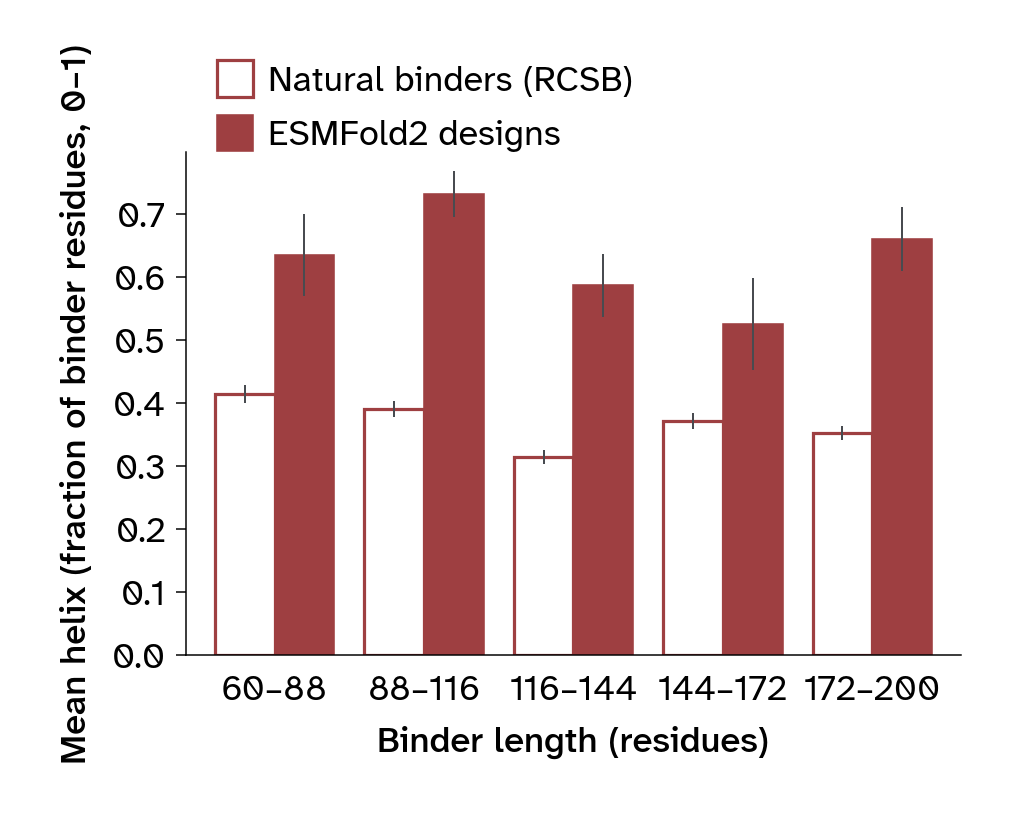

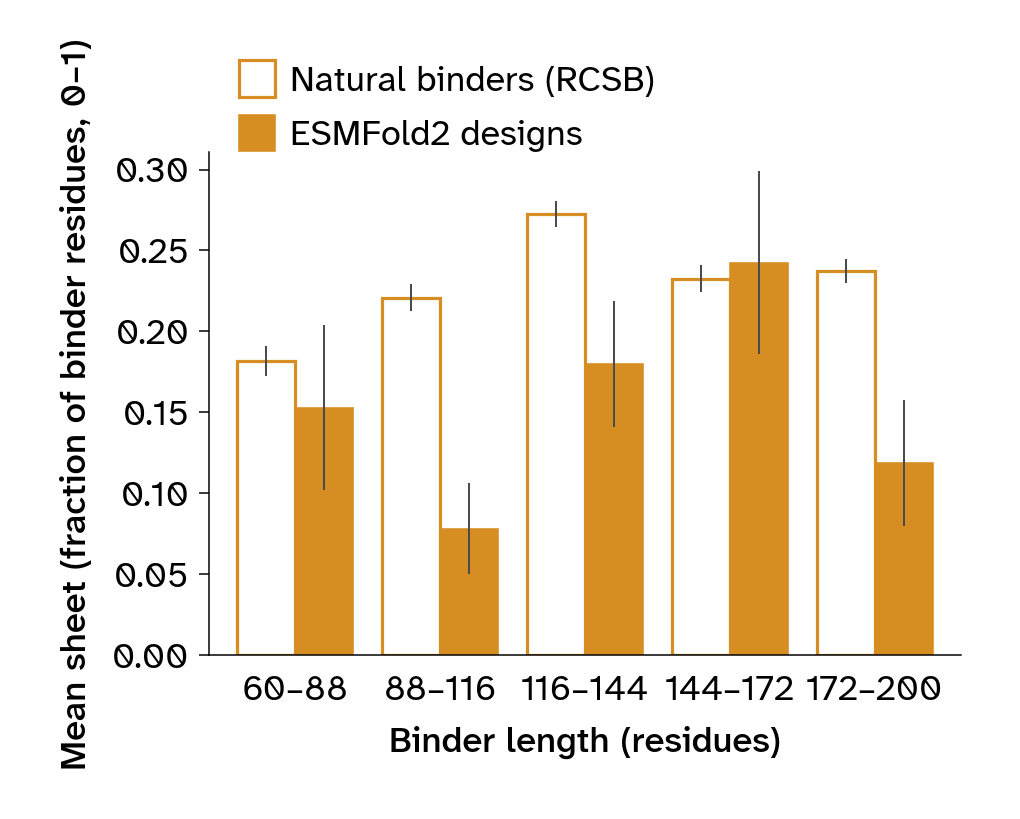

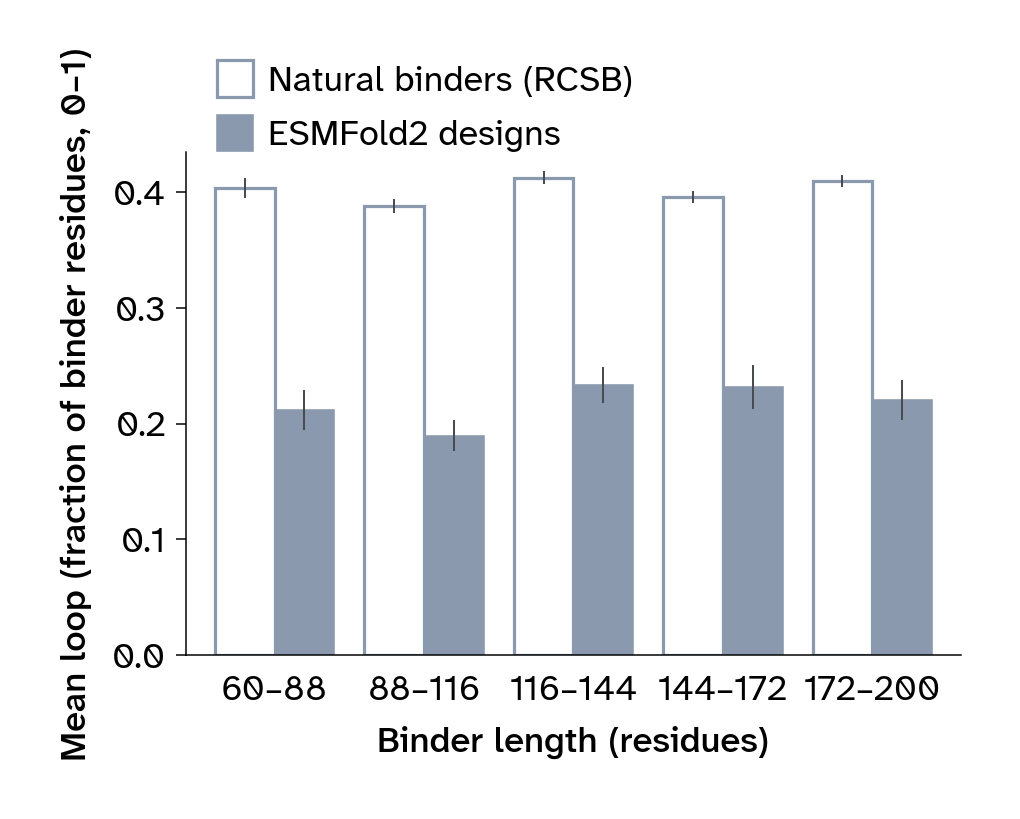

In [4]:
# | label: fig-composition
# | fig-alt:
# |   - "Bar chart comparing helix fractions of natural and designed binders across length bins."
# |   - "Bar chart comparing sheet fractions of natural and designed binders across length bins."
# |   - "Bar chart comparing loop fractions of natural and designed binders across length bins."
# | fig-cap: "Helix, sheet, and loop fractions of unsteered designs and the experimental reference, grouped into five binder-length bins. Unfilled bars show the natural reference from RCSB. Filled bars show designs. Each chain contributes once to its bin. Bars are means. Whiskers are standard errors across chains."
# | fig-subcap:
# |   - "Helix"
# |   - "Sheet"
# |   - "Loop"
# | layout-ncol: 2
# | code-fold: true
# | code-summary: "Measure unsteered designs and compare with the natural reference"

import numpy as np
from matplotlib import pyplot as plt

TARGETS = list(targets.TARGET_SPECS)
campaign_composition = {}
for target in TARGETS:
    campaign_composition[target, "vanilla"] = composition.measure_campaign(target, "vanilla")

designs = pd.concat(campaign_composition.values(), ignore_index=True)

length_edges = np.linspace(60, 200, 6)
length_summaries = {}
for state, columns in figures.STATES.items():
    reference_summary = composition.summarize_by_length(
        natural[columns.natural_column], natural["binder_sample_length_residues"], length_edges
    )
    design_summary = composition.summarize_by_length(
        designs[columns.design_column], designs["binder length (residues)"], length_edges
    )
    length_summaries[state] = {"natural": reference_summary, "designs": design_summary}
    figures.composition_comparison(reference_summary, design_summary, state, length_edges)

Unsteered ESMFold2 designs are substantially more helical than the natural reference, with correspondingly less sheet and loop (@fig-composition). In the pooled comparison, this pattern recurs across binder-length bins (@fig-composition).

## A helix penalty shifts designs toward sheets

The reference comparison suggests a practical opportunity to reduce the predominance of helices so that a campaign samples more of the sheet-containing compositions found in natural complexes. To test this, we added a term to the existing objective that penalizes helix-like geometry.

### The existing structural objective

The default structural loss combines intrabinder contacts, contacts between the target and binder, and a size-dependent compactness term:

$$
\mathcal{L}_{\mathrm{struct}}
= 0.5\,\mathcal{L}_{\mathrm{intra}}
+ 0.5\,\mathcal{L}_{\mathrm{inter}}
+ 0.2\,\mathcal{L}_{\mathrm{glob}}.
$$

The intrabinder term favors nonlocal contacts within the binder. The interface term asks each target residue for a contact with the binder, and the compactness term favors smaller predicted binder dimensions. For details, see @candido2026language.

### Penalizing helix-like distances

We use a local geometric feature of a helix: Residues four positions apart have nearby Cα atoms. The distogram gives the predicted probability distribution over residue-pair distances. For each eligible binder position, we sum the probability below 7 Å and average over positions:

$$
\mathcal{L}_{\mathrm{helix}}=\frac{1}{L-4}\sum_{i=1}^{L-4}
P(d_{i,i+4}<7\ \text{Å})\in[0,1].
$$

We excluded the final four residues from the average because they have no partner at this offset. The penalty acts only on the binder block of the distogram.

To steer sequence optimization, we then replace the default structural objective $\mathcal{L}_{\mathrm{struct}}$ with an objective that includes the weighted helicity penalty:

$$
\mathcal{L}^{\prime}_{\mathrm{struct}}
=\mathcal{L}_{\mathrm{struct}}+w\,\mathcal{L}_{\mathrm{helix}}.
$$

Increasing the weight $w$ makes these short $i,i+4$ distances more costly.

Note that the term $\mathcal{L}_{\mathrm{helix}}$ is a differentiable proxy for secondary structure, not a true secondary-structure assignment. A low value doesn't distinguish a strand from an irregular extended segment, and it doesn't specify how strands should pair. @fig-scene illustrates the distance criterion on an example protein.

:::{.callout-note collapse="true" title="Relationship to BindCraft's helicity loss"}

We developed this formulation before becoming aware of BindCraft's helicity loss [@pacesa2025bindcraft]. Both use the same underlying strategy of steering secondary structure by discouraging short intrabinder distances characteristic of helices. BindCraft's [implementation](https://github.com/martinpacesa/BindCraft/blob/7cd4ace1b7407adf66a50dfefa47de2270f5e4a9/functions/colabdesign_utils.py) averages a [negative-log contact probability](https://github.com/sokrypton/ColabDesign/blob/24a449493c9e60fc8fefd4981a4b83f7900b9110/colabdesign/af/loss.py) for binder residue pairs separated by three positions, using a 6 Å cutoff. Our formulation averages contact probabilities for pairs separated by four positions, using a 7 Å cutoff. We haven't made a direct comparison of the two formulations under matched conditions, but we note their conceptual similarity.
:::

In [5]:
# | label: fig-scene
# | role: group
# | aria-label: "Interactive 3D binder structure highlighting short i to i+4 contacts."
# | fig-cap: "A predicted binder colored by the coordinate-based distance criterion underlying the penalty. Red marks a Cα pair at positions $i$ and $i+4$ below 7 Å; each such pair contributes $1/(L-4)$ to the binary coordinate average, where $L$ is the binder length. The last four residues are unscored. Hovering shows the measured pair and distance."
# | code-fold: true
# | code-summary: "Visualize the helix-distance criterion on an example binder"

from analysis import scene

scene.loss_term_scene(paths.ASSETS / "example-complex.pdb").show()

3Dmol.js failed to load for some reason. Please check your browser console for error messages.

### Increasing the weight replaces helix with sheet and loop

We compared weights of 0, 0.5, 1.0, 2.0, and 5.0, with 30 seeds per condition on each target. @fig-scan-1 shows the mean composition pooled across all five targets; @fig-scan-2 shows the pooled distribution of helix fractions.

In [6]:
# | code-fold: true
# | code-summary: "Measure the target-by-weight comparison, with 30 designs per condition"

ARMS = list(targets.CAMPAIGN_ARMS)
for target in TARGETS:
    for arm in ARMS:
        if (target, arm) not in campaign_composition:
            campaign_composition[target, arm] = composition.measure_campaign(target, arm)

steered = pd.concat(campaign_composition.values(), ignore_index=True)
campaign_sizes = steered.groupby(["target", "arm"]).size()
assert campaign_sizes.eq(targets.N_SEEDS).all()

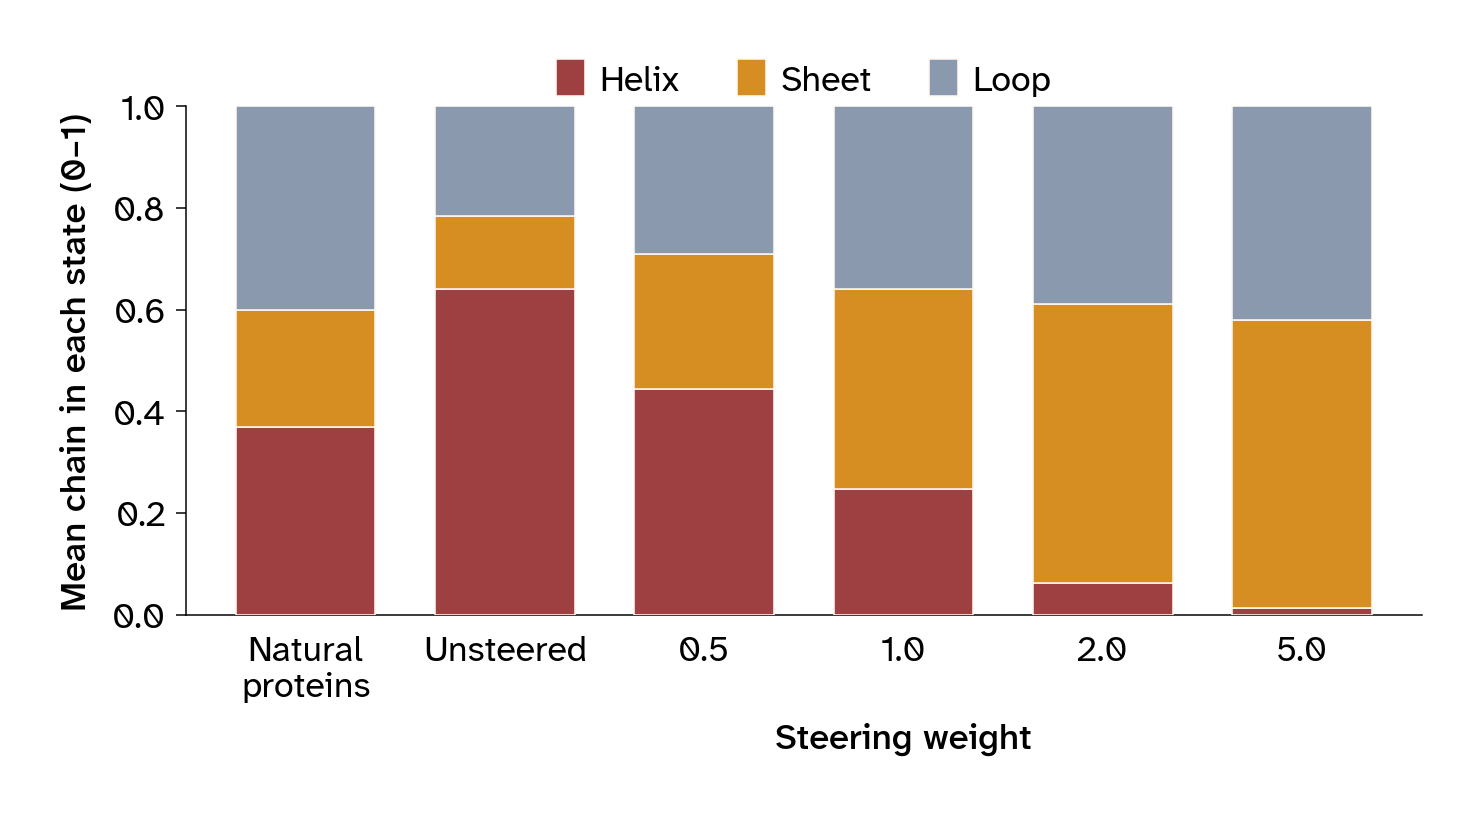

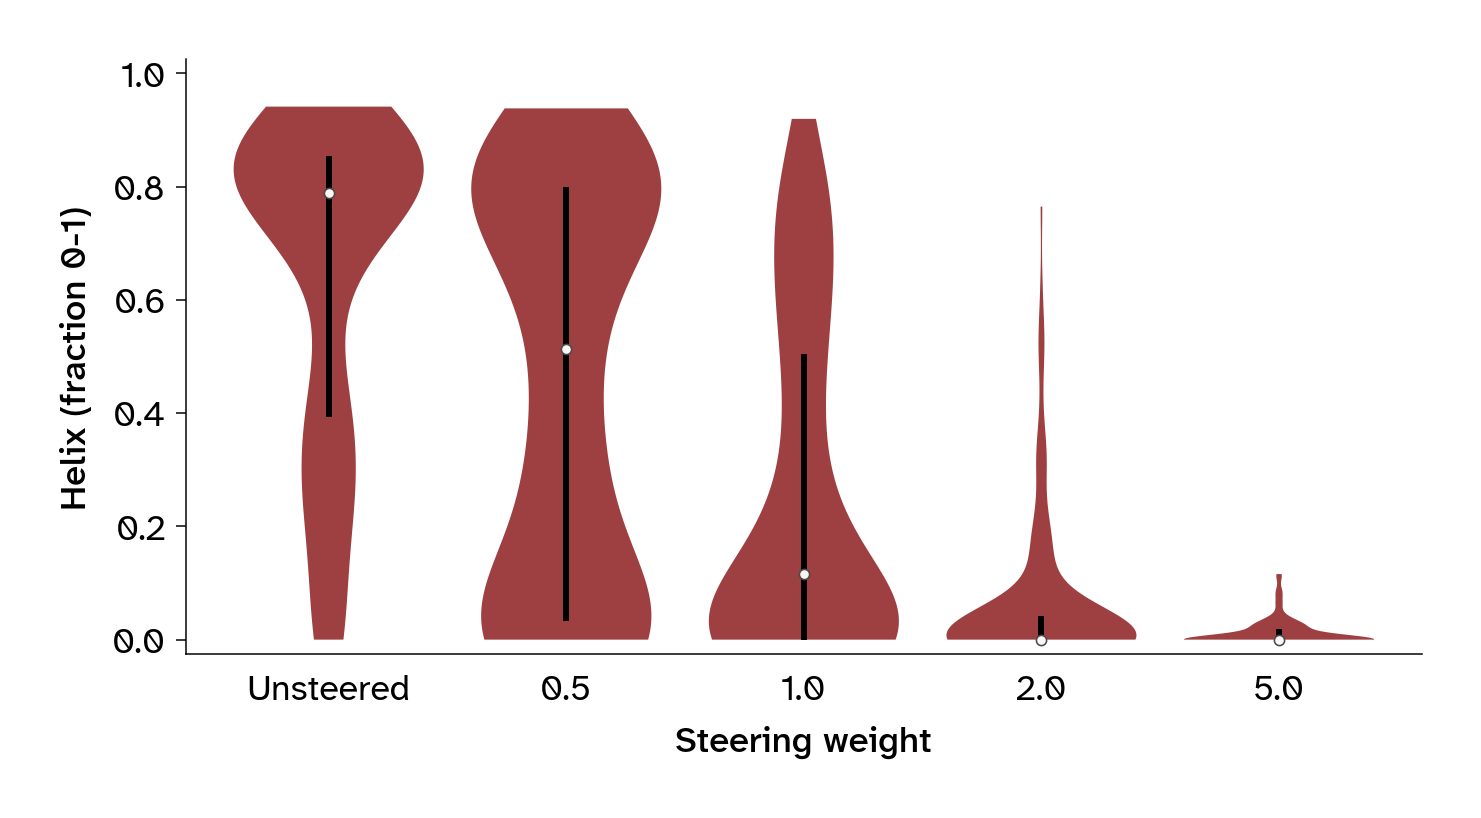

In [7]:
# | label: fig-scan
# | fig-alt:
# |   - "Stacked bars showing mean helix, sheet, and loop fractions across steering weights."
# |   - "Violin plots showing binder helix fractions across steering weights."
# | fig-cap: "Secondary-structure composition across steering weights, pooled across all five targets (150 designs per weight, with equal contributions from each target). PyDSSP assigns secondary structure from final binder structures predicted by ESMFold2-Experimental-Fast-Cutoff2025 and experimental structures for the natural reference."
# | fig-subcap:
# |   - "Mean helix, sheet, and loop fractions. The leftmost bar shows the natural reference, including all chains without resampling or weighting."
# |   - "Helix-fraction distributions. Violins are restricted to each group's observed range and scaled to equal maximum width. White dots mark medians. Thick vertical lines span the interquartile range."
# | layout-ncol: 1
# | code-fold: true
# | code-summary: "Pool chain composition by steering weight and inspect helix distributions"

composition_means = {}
for state, columns in figures.STATES.items():
    design_means = steered.groupby("arm")[columns.design_column].mean().reindex(ARMS)
    composition_means[state] = pd.concat(
        [pd.Series({"natural": natural[columns.natural_column].mean()}), design_means]
    )
composition_means = pd.DataFrame(composition_means)

figures.composition_means(composition_means)
figures.scan_violin(steered, ARMS, "helix")
plt.show()

@fig-scan-1 shows that penalizing helix-like distances increases both sheet and loop content. At the strongest weights, helices are almost absent, while sheets account for just over half of the mean composition.

The pooled distributions in @fig-scan-2 reveal heterogeneous responses to intermediate steering weights. In particular, at $w=0.5$, the helix-fraction distribution appears bimodal, with some designs remaining strongly helical, while others contain little helix. This pattern suggests that modest steering can substantially redirect some optimization trajectories while leaving others helix-rich. Both helix-rich and helix-poor designs also occur within individual targets (@fig-generality).

### The response occurs on all five targets

We next examined how individual targets contribute to the pooled response. @fig-generality shows the distributions of helix, sheet, and loop fractions for every target and weight.

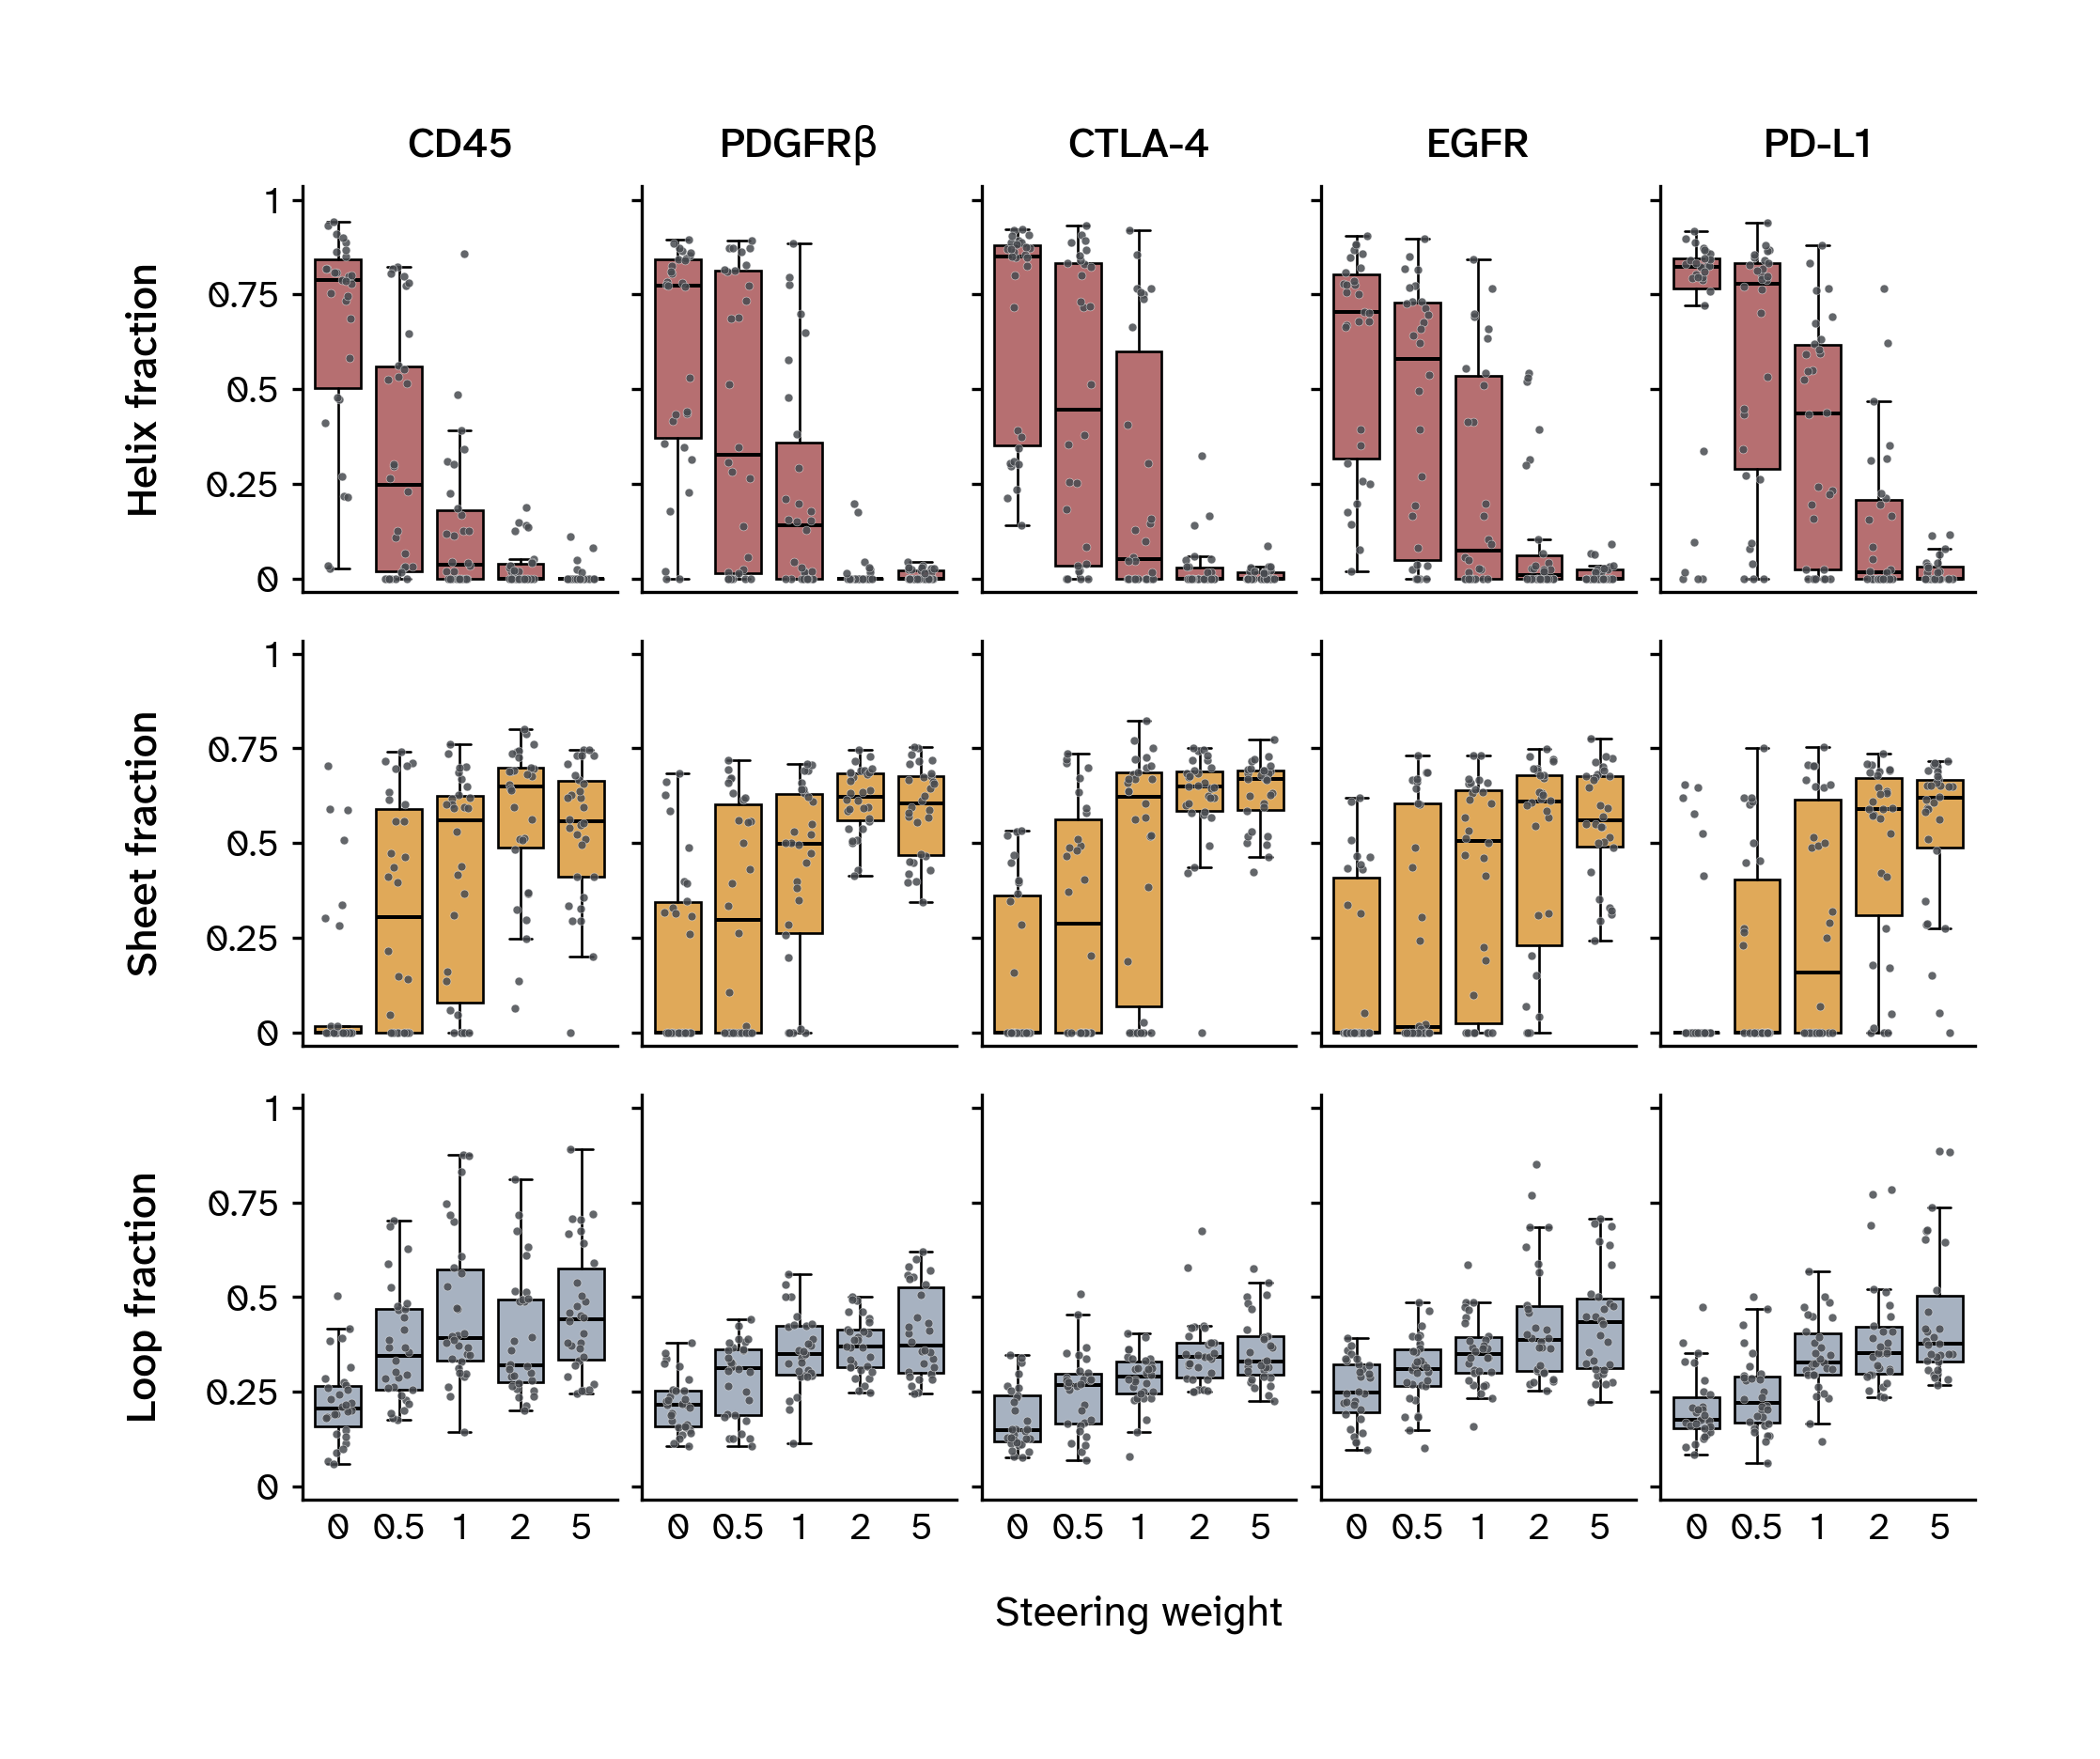

In [8]:
# | label: fig-generality
# | fig-alt: "Boxplots of helix, sheet, and loop fractions across steering weights for five targets."
# | fig-cap: "Final secondary-structure fractions across all five targets and steering weights (30 designs per target and weight). Rows show helix, sheet, and loop fractions; columns show targets. Points show individual designs."
# | out-width: "100%"
# | code-fold: true
# | code-summary: "Compare compositions by target"

TARGET_ORDER = (
    steered[steered["arm"] == "helix_mean_w05"]
    .groupby("target")["helix (fraction 0-1)"]
    .median()
    .sort_values()
    .index.tolist()
)
figures.scan_boxplots(steered, TARGET_ORDER, ARMS, ("helix", "sheet", "loop"))
plt.show()

Median helix decreased with weight on all five targets. Some targets, such as CD45, responded more strongly to intermediate weights than others, such as PD-L1, yet all reached a median helix fraction of zero by weight 5.0. Sheet and loop proportions increased as helix decreased, yielding sheet-rich designs with substantial loop content. The broad distributions at intermediate weights show that the same steering weight can yield very different compositions across seeds, as observed in @fig-scan-2.

### Steering lowers confidence

Steering produces more sheet-rich designs, but does it retain enough high-confidence candidates to make that change useful for a design campaign? We assessed confidence in the binder–target arrangement using the interface predicted template modeling score (ipTM), and confidence in local binder structure using the binder's predicted local distance difference test (pLDDT) score. We used ESMFold2-Experimental-Cutoff2025 for both scores and all confidence screens. This non-Fast model wasn't used for sequence optimization or trajectory selection. Secondary-structure fractions come from the saved Fast-model structures. @fig-cost and @tbl-cost show how confidence changes across the full population of designs.

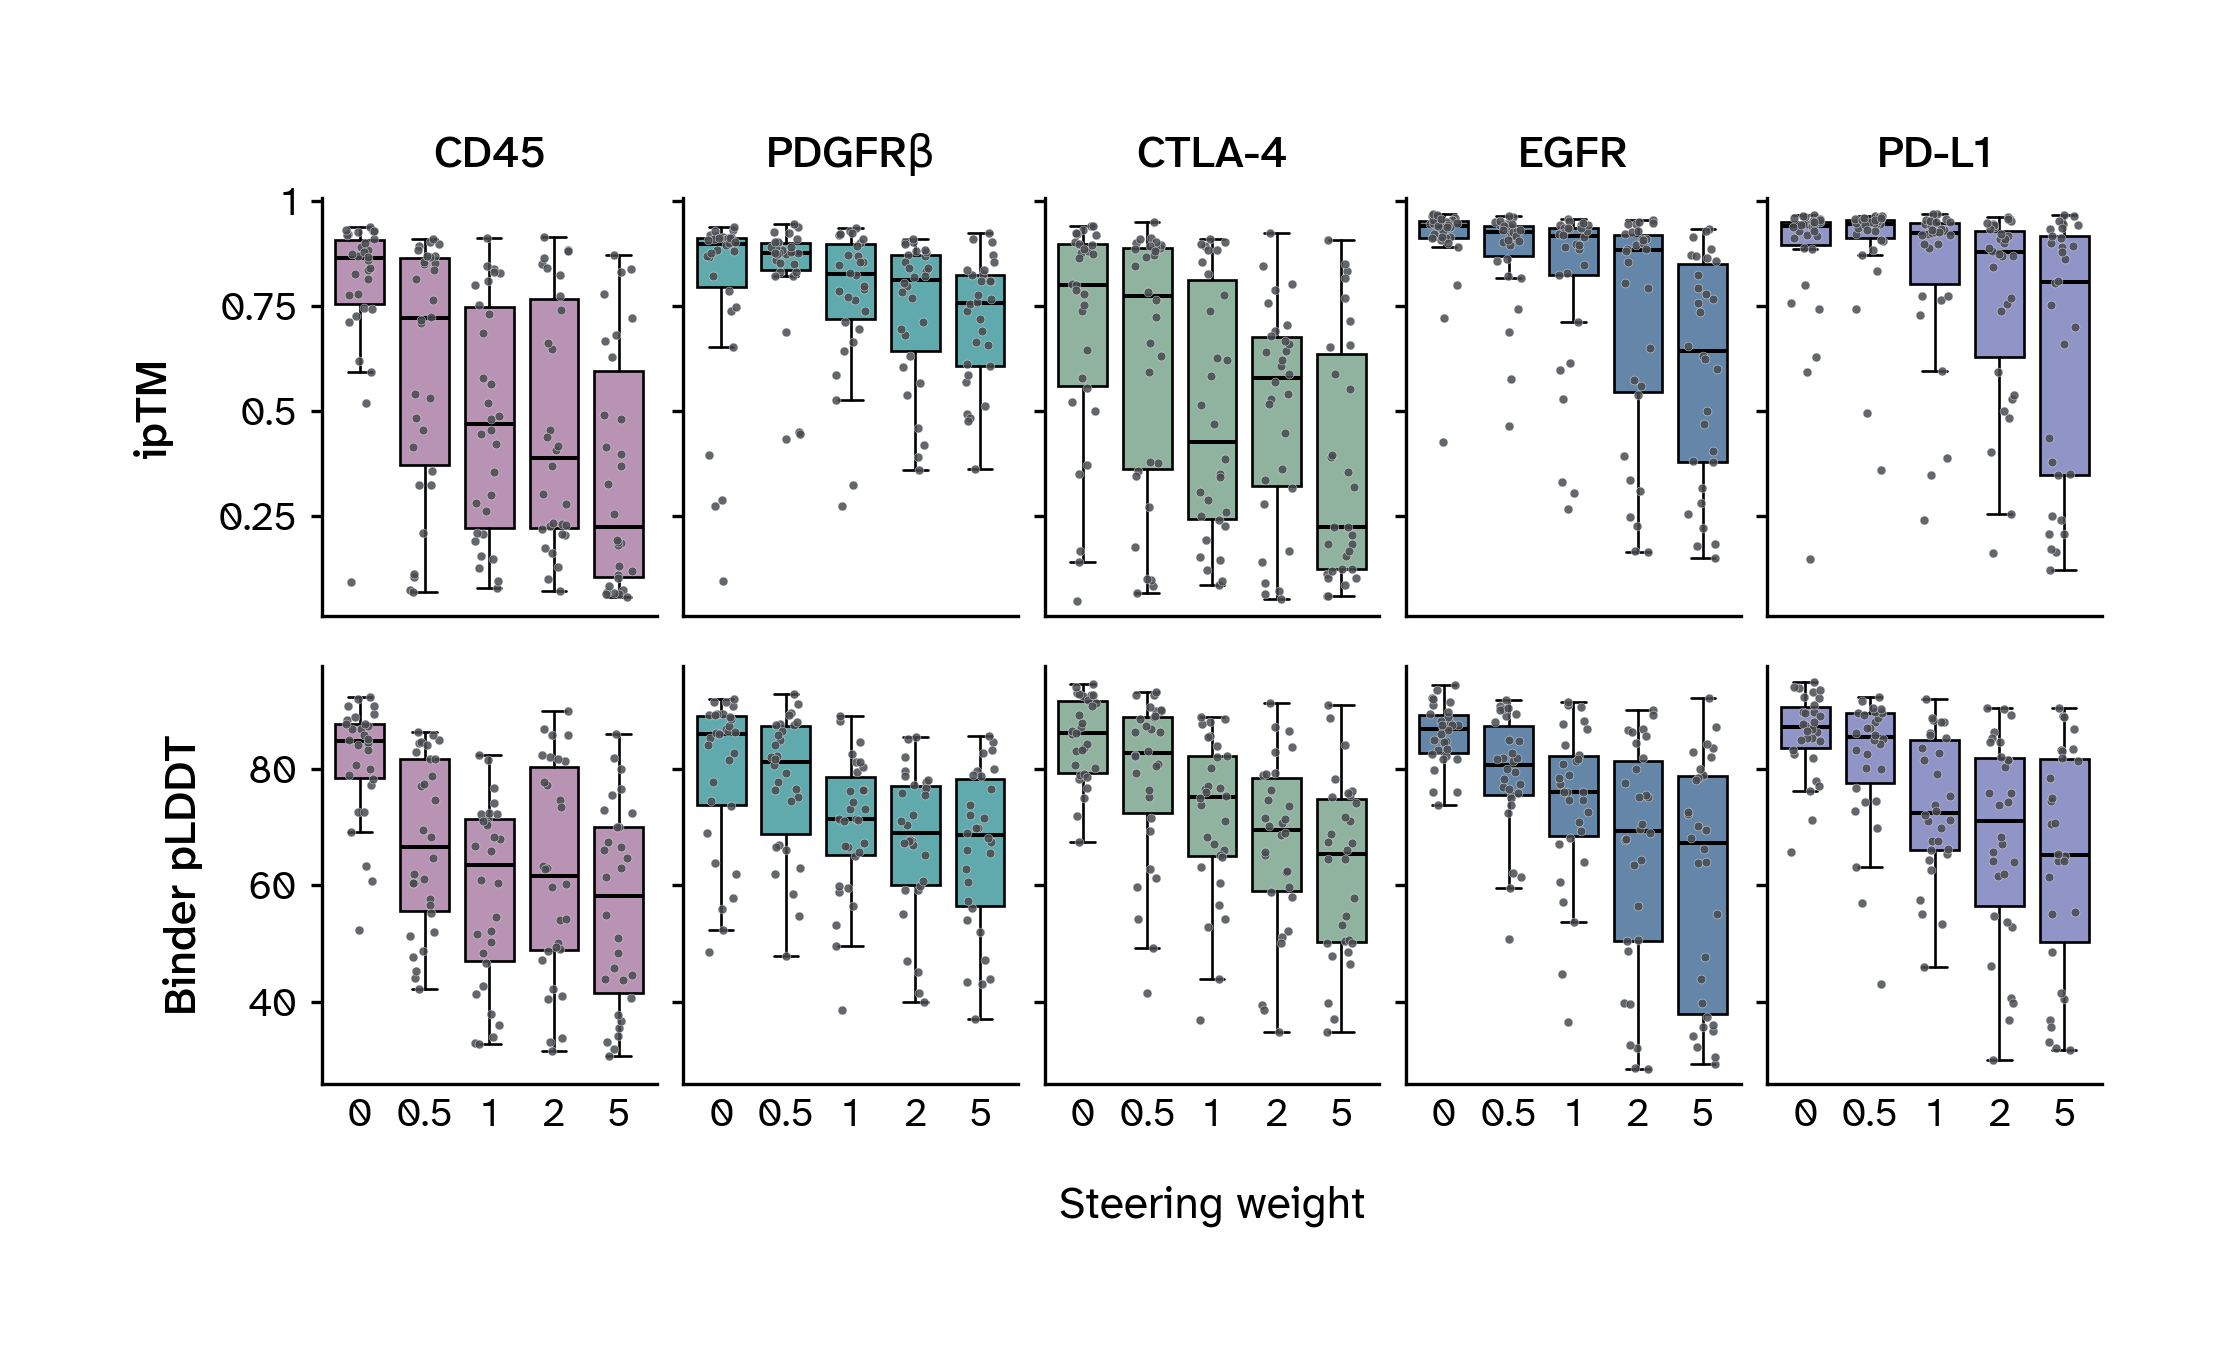

In [9]:
# | label: fig-cost
# | fig-alt: "Boxplots of interface and binder confidence across steering weights for five targets."
# | fig-cap: "ipTM (top) and pLDDT (bottom), both from ESMFold2-Experimental-Cutoff2025, across steering weights, with 30 designs per target and weight. Points show individual designs."
# | out-width: "100%"
# | code-fold: true
# | code-summary: "Compare final confidence distributions by target and steering weight"

figures.scan_boxplots(steered, TARGET_ORDER, ARMS, ("iptm", "plddt"))
plt.show()

In [10]:
# | label: tbl-cost
# | tbl-cap: "Median ipTM and binder pLDDT from ESMFold2-Experimental-Cutoff2025 by target and steering weight."
# | code-fold: true
# | code-summary: "Calculate median confidence by target and steering weight"

from analysis import tables
from IPython.display import display

cost_metric_labels = {
    "iptm (0-1)": "ipTM",
    "binder pLDDT (0-100)": "Binder pLDDT",
}
cost_tables = {}
for column, label in cost_metric_labels.items():
    cost_tables[label] = (
        steered.groupby(["target", "arm"])[column]
        .median()
        .unstack("arm")
        .reindex(index=TARGET_ORDER, columns=ARMS)
    )

cost_table = pd.concat(cost_tables, names=["Metric", "Target"])
display(tables.confidence(cost_table))

Both confidence measures generally decline as steering increases, although the size of the decline depends on the target. EGFR and PD-L1 retain relatively high interface confidence, while CD45 shows a more pronounced reduction. Even at strong steering weights, some candidates retain high confidence scores. We therefore counted how many designs pass the confidence screen and how many also meet the sheet-content requirement.

To distinguish these outcomes, we applied two in silico screens (@tbl-screen-criteria). The quality screen uses pLDDT and ipTM thresholds. The combined screen additionally requires a predicted sheet fraction above 0.40. The table below shows the thresholds for both screens.

| Screen | Requirements |
|---|---|
| Quality | ipTM above 0.85 and binder pLDDT above 80 |
| Quality + sheet content | Quality criteria and sheet fraction above 0.40 |

: Criteria defining a candidate that passes each in silico screen. {#tbl-screen-criteria}

@tbl-sheet-screen reports the number of candidates passing each screen, so we can compare the loss of high-confidence candidates directly with the yield of candidates that also have the desired composition.

In [11]:
# | label: tbl-sheet-screen
# | tbl-cap: "Candidates passing each in silico screen by target and steering weight. Confidence scores come from ESMFold2-Experimental-Cutoff2025; sheet fractions come from Fast-Cutoff2025 structures. Pass rates use all designs at that weight as the denominator."
# | code-fold: true
# | code-summary: "Count candidates passing each screen"

quality_pass = (steered["iptm (0-1)"] > composition.MIN_IPTM) & (
    steered["binder pLDDT (0-100)"] > composition.MIN_BINDER_PLDDT
)
screens = {
    "Quality": quality_pass,
    "Quality + sheet content": quality_pass
    & (steered["sheet (fraction 0-1)"] > composition.MIN_SHEET_FRACTION),
}
screen_denominators = steered.groupby("arm").size().reindex(ARMS)
screen_tables = {}
for screen, passed in screens.items():
    counts = (
        steered.assign(passed=passed)
        .groupby(["target", "arm"])["passed"]
        .sum()
        .unstack("arm")
        .reindex(index=TARGET_ORDER, columns=ARMS)
    )
    counts.loc["Total"] = counts.sum()
    counts.loc["Pass rate"] = counts.loc["Total"] / screen_denominators
    screen_tables[screen] = counts

screen_table = pd.concat(screen_tables, names=["Screen", "Target"])
display(tables.screen_counts(screen_table))

Steering reduced the pooled number of candidates passing the quality screen, yet every tested steering weight yielded more candidates passing the combined screen than unsteered design. At weight 2.0, quality passes fell from 94 to 28, while passes for the combined screen rose from 13 to 27. Nearly all candidates that retained high confidence at this weight also met the sheet requirement. **Steering therefore produced a smaller pool of high-confidence candidates, enriched in the desired composition**.

Overall, steering away from ESMFold2's helix preference comes at the cost of lower in silico confidence. However, the biological meaning of that reduction remains unresolved. ESMFold2's confidence scores could be well calibrated with reality, with sheet-rich designs scoring lower because they're less likely to fold and bind well. Alternatively, the scores could underestimate viable sheet-rich designs. The model's preference for generating helical designs (@fig-composition) motivates this possibility, but doesn't establish whether its confidence scores are miscalibrated. Experimentally testing the designs could settle this.

## Helicity diverges while sequences remain soft

The final structures show how strongly steering changes composition, but not when those differences emerge during optimization. We tracked the helix proxy, interface-confidence proxy, and sequence entropy throughout optimization to see how the structural predictions develop as the soft sequence hardens (@fig-trace).

In [12]:
# | code-fold: true
# | code-summary: "Calculate per-step medians across designs for each steering weight"

campaign_traces = {}
for target in TARGETS:
    for arm in ARMS:
        campaign_traces[target, arm] = loss_trace.load_campaign(target, arm)

trace = pd.concat(campaign_traces.values(), ignore_index=True)

trace_columns = {
    "helix_mean": "helix_mean (0-1)",
    "iptm_proxy": "distogram iptm proxy (0-1)",
    "entropy": "sequence entropy (bits)",
}
trace_medians = (
    trace.groupby(["arm", "step (index)"])[list(trace_columns.values())].median().reset_index()
)

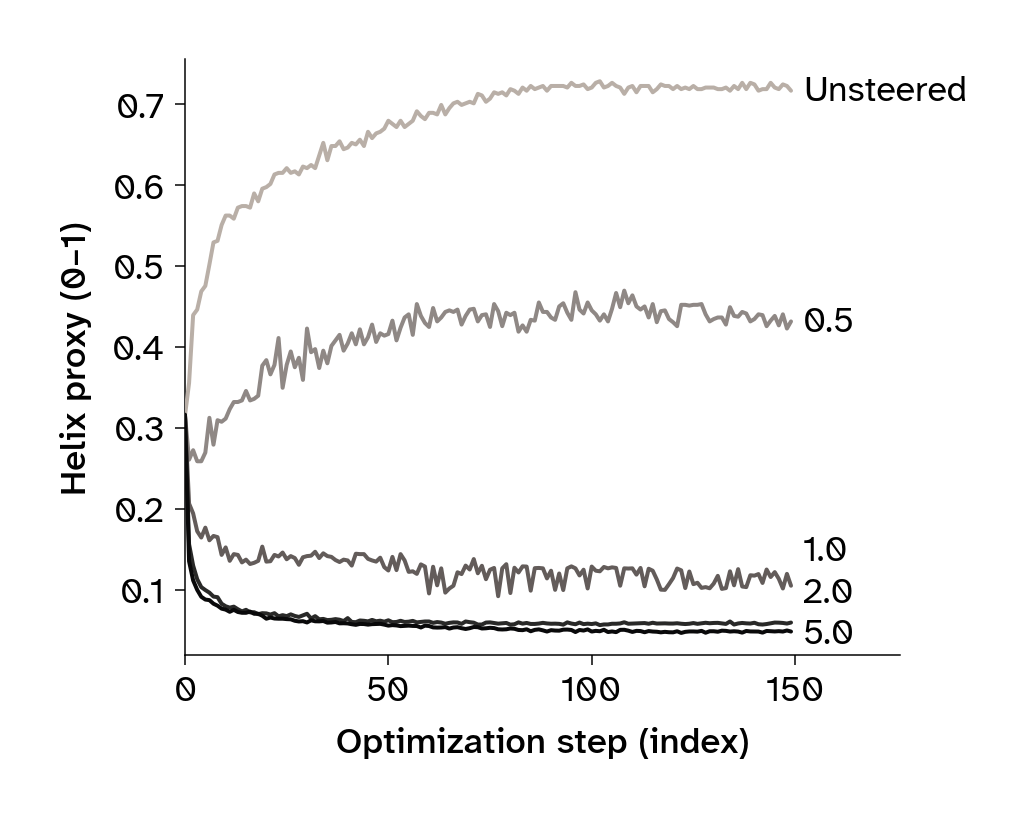

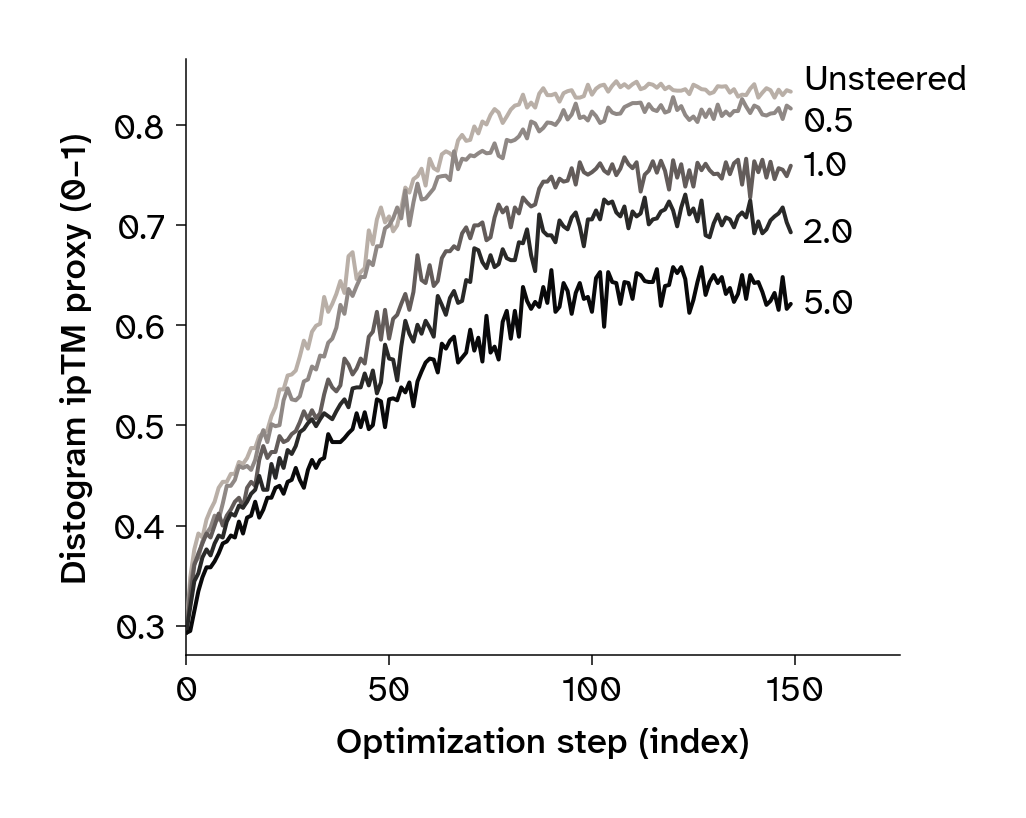

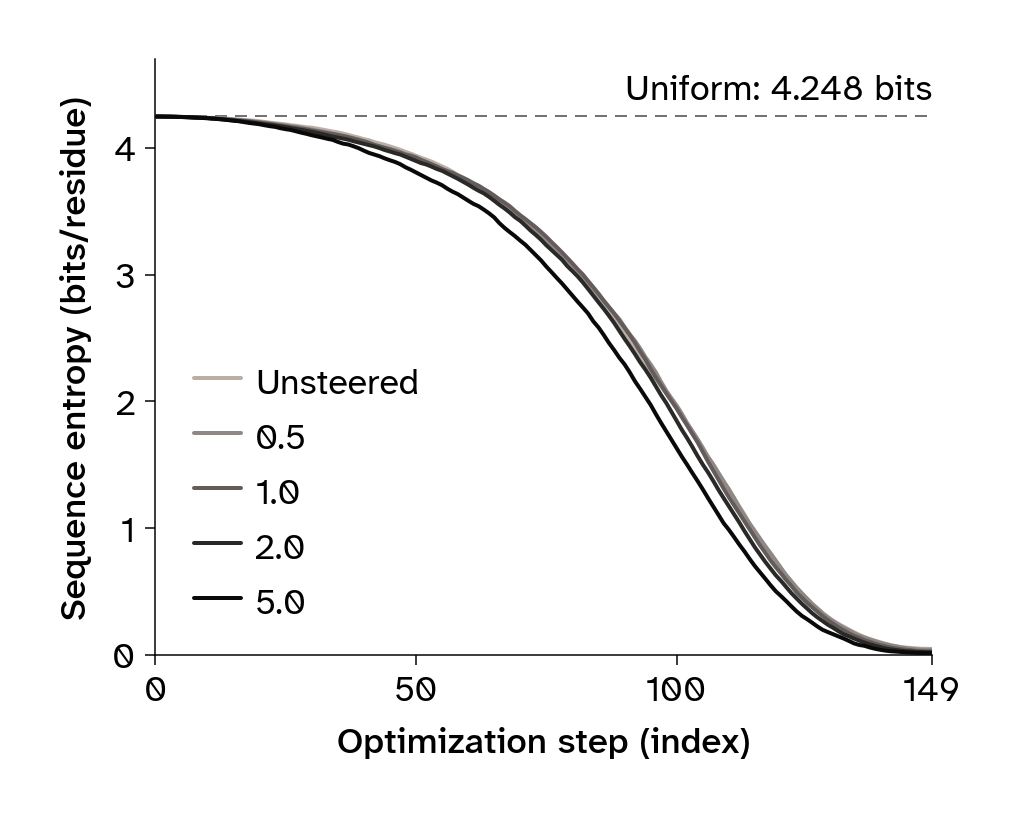

In [13]:
# | label: fig-trace
# | fig-alt:
# |   - "Line plots of median helix proxy over optimization steps at different steering weights."
# |   - "Line plots of median interface confidence proxy over optimization steps at different steering weights."
# |   - "Line plots of median sequence entropy over optimization steps at different steering weights."
# | fig-cap: "Median optimization diagnostics across 150 designs per condition, pooling five targets. The ipTM proxy summarizes interface confidence from the distogram, which the model learns to predict during training. Sequence entropy is the mean per-residue entropy of the soft amino acid probabilities. The dashed line marks the uniform maximum over 19 amino acids (cysteine probability is initialized to 0)."
# | fig-subcap:
# |   - 'Helix proxy ($\mathcal{L}_{\mathrm{helix}}$)'
# |   - "ipTM proxy"
# |   - "Sequence entropy"
# | layout-ncol: 2
# | code-fold: true
# | code-summary: "Plot median helicity, interface proxy, and sequence entropy during optimization"

from matplotlib import pyplot as plt

for metric in trace_columns:
    panel = figures.trace_summary(trace_medians, metric, ARMS)
    display(panel)
    plt.close(panel)

Steering redirected structural predictions before optimization strongly favored particular amino acids. The early soft-sequence stage therefore offers a point of control over the structures that emerge. This sensitivity also suggests that small changes to the starting amino acid probabilities could influence design outcomes.

:::{.callout-note collapse="true" title="Individual trajectories show the range of responses"}

The median trajectories in @fig-trace summarize runs with very different outcomes, even at the same steering weight. The 30 CD45 runs at weight 1.0 include both low- and high-helicity endpoints (@fig-seeds).

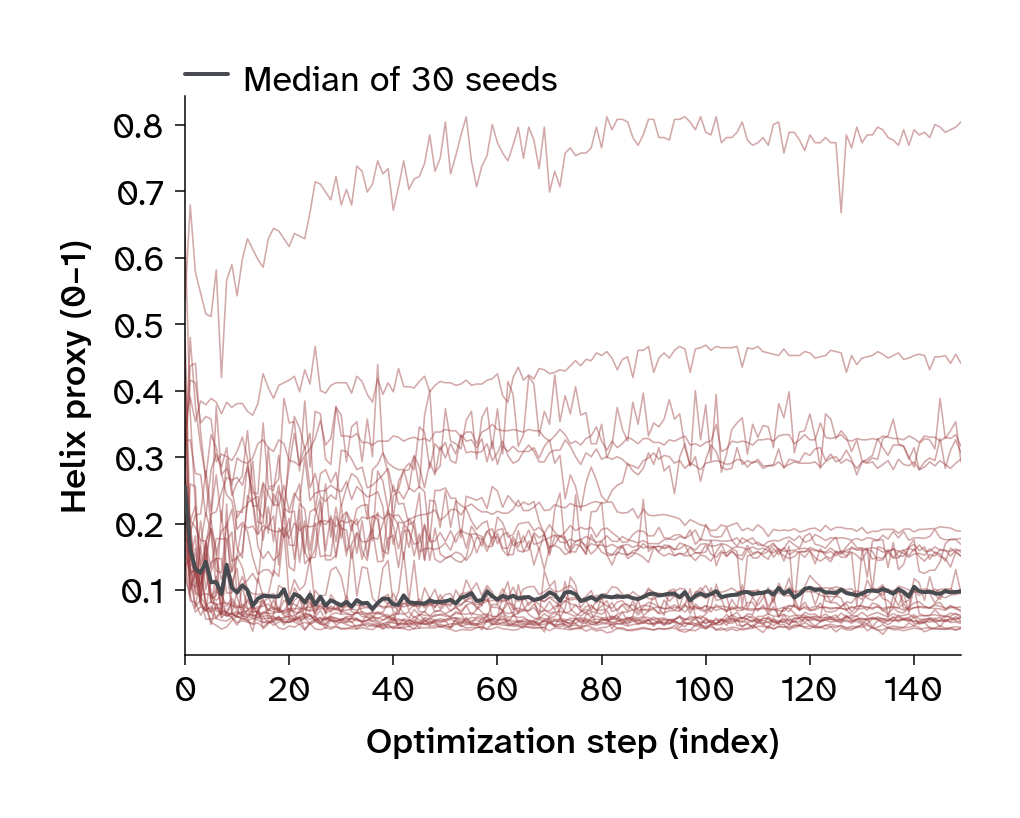

In [14]:
# | label: fig-seeds
# | fig-alt: "Line plots of individual CD45 helix proxy trajectories and their median at steering weight 1.0."
# | fig-cap: "Distogram helicity trajectories for all 30 CD45 runs at weight 1.0. Thin lines show individual seeds and the thick line shows their median. These values are the optimization proxy, not final PyDSSP helix fractions."
# | code-fold: true
# | code-summary: "Inspect individual CD45 trajectories and their final helicity proxies"

selected_traces = trace[(trace["target"] == "cd45_d3d4") & (trace["arm"] == "helix_mean_w10")]
final_proxy = selected_traces.loc[
    selected_traces["step (index)"] == targets.SGD_STEPS - 1, "helix_mean (0-1)"
]
panel = figures.seed_traces(selected_traces, "cd45_d3d4", "helix_mean_w10", "helix_mean")
display(panel)
plt.close(panel)

:::

## Conclusion

Changing the design objective gave us control over ESMFold2's secondary-structure preference without retraining the model. Across five targets, a local distance penalty shifted designs toward sheets and loops. Although average confidence fell, steering produced more candidates that met both our sheet-content and confidence criteria. Weight 2.0 yielded the largest pooled count, but the most productive weight differed by target.

The response began while amino acid probabilities were still close to uniform. We could therefore redirect structural preferences before optimization strongly favored particular residue identities, making the earliest design steps a useful point for intervention. This also suggests that changing the starting amino acid probabilities could influence design outcomes.

More broadly, loss steering offers a way to adapt a pretrained design workflow to the needs of a campaign. Secondary-structure composition is one property we can influence through the objective. Other differentiable terms could offer control over additional properties.

The main unresolved question is whether lower confidence reflects a biological cost. Steered candidates may fold or bind less well, or the model may underestimate viable sheet-rich designs. Its preference for generating helices gives us a reason to investigate the latter possibility, but doesn't establish that its confidence estimates are less reliable for sheets. That distinction matters for screening: Lower scores could help reject poor designs or cause us to discard useful ones. Testing whether steered candidates fold and bind their intended targets would help determine which explanation holds.

## Next steps

An experimental next step would be to synthesize steered and unsteered candidates and test whether they fold and bind their intended targets. Comparing these measurements with predicted confidence would help establish whether steering expands the pool of useful binders and how well the scores guide their selection.

The early response to steering also motivates testing whether the starting amino acid distributions can influence final designs. Structural preferences diverged while the soft sequences were still close to uniform, showing that those preferences can take shape before optimization commits to particular residue identities.

## Appendix: Early steering has a lasting effect

The trajectories show an early separation between steered and unsteered runs (@fig-trace). This raises two questions: Can a penalty introduced later still redirect composition, and can we withdraw early steering while preserving that change?

We tested these questions on PD-L1 with two parameter scans. For the *onset* scan, we varied the optimization step at which we first applied the helicity penalty and then kept it active for the rest of the run. For the *withdrawal* scan, we applied the penalty from the start and varied the step at which we removed it. Both scans used weight 2.0, which we chose because it produced a strong composition response in @fig-trace. Each condition contains 30 designs, with 150 optimization steps per design (@fig-schedule).

:::{.callout-note title="Comparing steering schedules"}

Individual designs aren't seed-reproducible here. The following campaigns therefore compare outcome distributions under different schedules, rather than tracking the same design with and without a change in timing.

:::

In [15]:
# | code-fold: true
# | code-summary: "Measure onset and withdrawal campaigns, reusing the shared endpoints"

SCAN_TARGET = "pdl1_igv"
scans = {"onset": targets.ONSET_SCAN, "withdrawal": targets.RELEASE_SCAN}
schedule_arms = set(scans["onset"].values()) | set(scans["withdrawal"].values())
for arm in sorted(schedule_arms):
    key = (SCAN_TARGET, arm)
    if key not in campaign_composition:
        campaign_composition[key] = composition.measure_campaign(*key)
        campaign_traces[key] = loss_trace.load_campaign(*key)

schedule_designs, schedule_medians = {}, {}
for name, scan in scans.items():
    schedule_designs[name] = pd.concat(
        [campaign_composition[SCAN_TARGET, arm] for arm in scan.values()], ignore_index=True
    )
    scan_trace = pd.concat([campaign_traces[SCAN_TARGET, arm] for arm in scan.values()])
    schedule_medians[name] = (
        scan_trace.groupby(["arm", "step (index)"])[["helix_mean (0-1)"]].median().reset_index()
    )

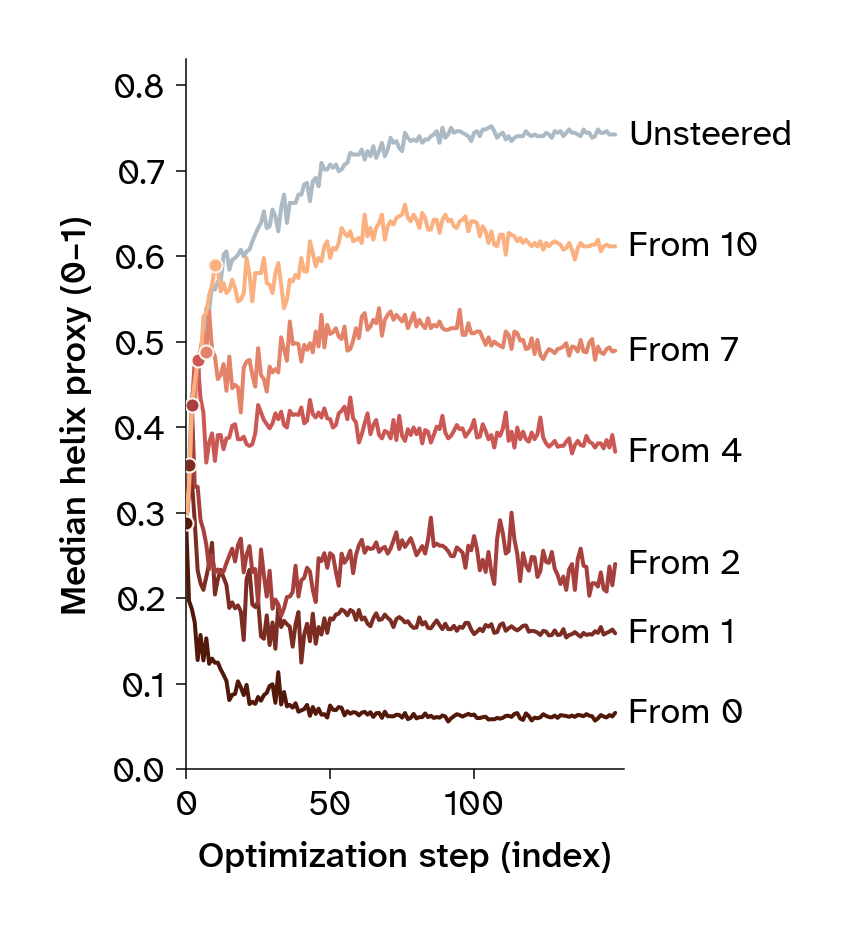

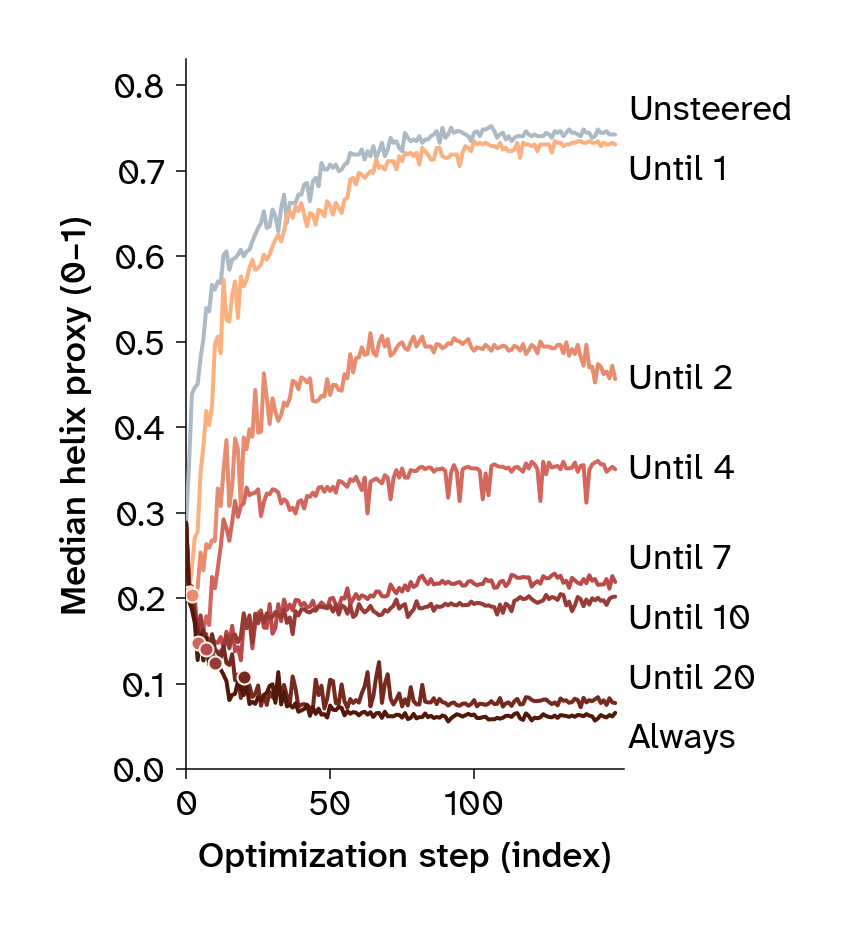

In [16]:
# | label: fig-schedule
# | fig-alt:
# |   - "Line plots of median PD-L1 helix proxy with steering starting at different optimization steps."
# |   - "Line plots of median PD-L1 helix proxy with steering stopping at different optimization steps."
# | fig-cap: "Median helicity proxy during PD-L1 optimization with delayed or withdrawn steering (weight 2.0; 30 designs per condition; 150 steps). Labels mark when the penalty begins or ends. Dots mark switching steps."
# | fig-subcap:
# |   - "Delaying the start of steering"
# |   - "Stopping steering early"
# | layout-ncol: 2
# | code-fold: true
# | code-summary: "Compare helicity trajectories under delayed and withdrawn steering"

from matplotlib import pyplot as plt

drawn_steps = {
    "onset": (targets.SGD_STEPS, 0, 1, 2, 4, 7, 10),
    "withdrawal": (0, 1, 2, 4, 7, 10, 20, targets.SGD_STEPS),
}
for panel in figures.schedule_trace_panels(schedule_medians, scans, drawn_steps):
    display(panel)
    plt.close(panel)

In [17]:
# | code-fold: true
# | code-summary: "Calculate final sheet fractions separately from the optimization proxy"
# | output: false

schedule_sheet_medians = {}
for name, scan in scans.items():
    median_sheet = schedule_designs[name].groupby("arm")["sheet (fraction 0-1)"].median()
    schedule_sheet_medians[name] = pd.Series(
        {step: median_sheet[arm] for step, arm in scan.items()}, name="Median sheet fraction"
    )

In this PD-L1 experiment, the reduction in the median helix proxy persisted after early steering was withdrawn. The penalty therefore didn’t need to remain active throughout optimization to maintain a lower helix proxy. This suggests that a brief early intervention can have a lasting effect on the subsequent optimization trajectory.